## Interval Analysis

In [1]:
# !pip install tensorboardX

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
# from tensorboardX import SummaryWriter

use_cuda = torch.cuda.is_available()
device = torch.device("cuda" if use_cuda else "cpu")
batch_size = 64

np.random.seed(42)
torch.manual_seed(42)
if use_cuda:
    torch.cuda.manual_seed_all(42)
print(f"Using device:{device}")

## Dataloaders
train_dataset = datasets.MNIST('mnist_data/', train=True, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## Simple NN. You can change this if you want. If you change it, mention the architectural details in your report.
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc = nn.Linear(28*28, 200)
        self.fc2 = nn.Linear(200,10)

    def forward(self, x):
        x = x.view((-1, 28*28))
        x = F.relu(self.fc(x))
        x = self.fc2(x)
        return x

class Normalize(nn.Module):
    def forward(self, x):
        return (x - 0.1307)/0.3081

# Add the data normalization as a first "layer" to the network
# this allows us to search for adverserial examples to the real image, rather than
# to the normalized image
model = nn.Sequential(Normalize(), Net())

model = model.to(device)
model.train()


Using device:cuda


100%|██████████| 9.91M/9.91M [00:00<00:00, 18.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 494kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.64MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 14.2MB/s]


Sequential(
  (0): Normalize()
  (1): Net(
    (fc): Linear(in_features=784, out_features=200, bias=True)
    (fc2): Linear(in_features=200, out_features=10, bias=True)
  )
)

In [2]:
def train_model(model, num_epochs):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for i, data in enumerate(train_loader, 0):
            images, labels = data
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader):.3f}')

def test_model(model):
    model.eval()
    with torch.no_grad():
        correct = 0
        total = 0
        for data in test_loader:
            images, labels = data
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        accuracy = 100*correct/total
        print(f'Clean test accuracy: {accuracy:.2f}%')
        return accuracy

In [3]:
train_model(model, 15)
clean_accuracy=test_model(model)

Epoch 1/15, Loss: 0.593
Epoch 2/15, Loss: 0.297
Epoch 3/15, Loss: 0.248
Epoch 4/15, Loss: 0.215
Epoch 5/15, Loss: 0.190
Epoch 6/15, Loss: 0.170
Epoch 7/15, Loss: 0.155
Epoch 8/15, Loss: 0.142
Epoch 9/15, Loss: 0.130
Epoch 10/15, Loss: 0.121
Epoch 11/15, Loss: 0.113
Epoch 12/15, Loss: 0.106
Epoch 13/15, Loss: 0.099
Epoch 14/15, Loss: 0.093
Epoch 15/15, Loss: 0.088
Clean test accuracy: 97.07%


### Write the interval analysis for the simple model

In [4]:
## TODO: Write the interval analysis for the simple model
## you can use https://github.com/Zinoex/bound_propagation



In [5]:
def linear_interval(lower, upper, layer):
    center = (lower+upper) / 2
    radius = (upper-lower) / 2
    output_center = F.linear(center, layer.weight, layer.bias)
    output_radius = F.linear(radius, layer.weight.abs(), None)
    return output_center-output_radius, output_center+output_radius

def interval_forward(model, images, epsilon):
    lower = torch.clamp(images-epsilon, 0.0, 1.0)
    upper = torch.clamp(images+epsilon, 0.0, 1.0)
    normalize = model[0]
    network = model[1]

    lower = normalize(lower).flatten(start_dim=1)
    upper = normalize(upper).flatten(start_dim=1)
    lower, upper = linear_interval(lower, upper, network.fc)
    lower = F.relu(lower)
    upper = F.relu(upper)
    lower, upper = linear_interval(lower, upper, network.fc2)
    return lower, upper

def margin_lower_bounds(logit_lower, logit_upper, labels):
    true_class_lower = logit_lower.gather(1, labels.unsqueeze(1))
    margins = true_class_lower - logit_upper
    margins.scatter_(1, labels.unsqueeze(1), float("inf"))
    return margins

@torch.no_grad()
def verified_accuracy(model, loader, epsilon):
    model.eval()
    verified_count = 0
    total = 0
    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)
        lower, upper = interval_forward(model, images, epsilon)
        margins = margin_lower_bounds(lower, upper, labels)
        verified = (margins>=0).all(dim=1)
        verified_count += verified.sum().item()
        total+=labels.size(0)
    return 100.0*verified_count / total

In [6]:
# Test
model.eval()
sample_images, _ = next(iter(test_loader))
sample_images = sample_images[:8].to(device)
with torch.no_grad():
    lower, upper = interval_forward(model, sample_images, epsilon=0.0)
    logits = model(sample_images)
assert torch.allclose(lower, logits, atol=1e-5)
assert torch.allclose(upper, logits, atol=1e-5)
print("Zero-radius check passed.")


Zero-radius check passed.


epsilon=0.01, verified accuracy=31.90%
epsilon=0.02, verified accuracy=1.09%
epsilon=0.03, verified accuracy=0.01%
epsilon=0.04, verified accuracy=0.00%
epsilon=0.05, verified accuracy=0.00%
epsilon=0.06, verified accuracy=0.00%
epsilon=0.07, verified accuracy=0.00%
epsilon=0.08, verified accuracy=0.00%
epsilon=0.09, verified accuracy=0.00%
epsilon=0.10, verified accuracy=0.00%

Clean accuracy: 97.07%
Verification time: 12.4 seconds


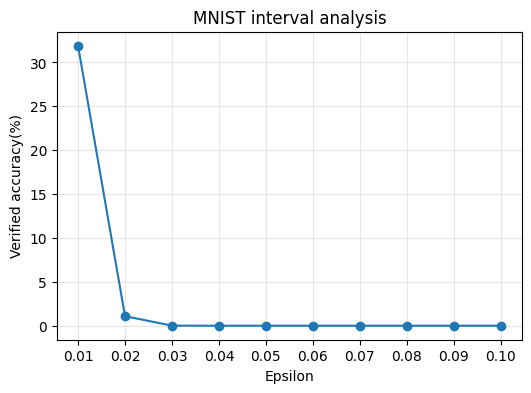

In [7]:
# experiment
epsilons = np.linspace(0.01, 0.10, 10)
verified_results = []
start_time = time.perf_counter()
for epsilon in epsilons:
    accuracy = verified_accuracy(model, test_loader, float(epsilon))
    verified_results.append(accuracy)
    print(f"epsilon={epsilon:.2f}, verified accuracy={accuracy:.2f}%")
elapsed = time.perf_counter() - start_time
print(f"\nClean accuracy: {clean_accuracy:.2f}%")
print(f"Verification time: {elapsed:.1f} seconds")

assert np.all(np.diff(verified_results) <= 1e-9)
plt.figure(figsize=(6, 4))
plt.plot(epsilons, verified_results, marker="o")
plt.xlabel("Epsilon")
plt.ylabel("Verified accuracy(%)")
plt.title("MNIST interval analysis")
plt.xticks(epsilons)
plt.grid(alpha=0.3)
plt.show()